# 02 — Sales Exploratory Data Analysis

Sales trends, product performance, and interpretation.

## 1. Business questions

Explore monthly sales patterns, leading products, and country-level transaction distribution.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = Path.cwd().parent

REPORTS = ROOT / "reports"
PROCESSED = ROOT / "data" / "processed"
FIGURES = REPORTS / "figures"

print("Project root:", ROOT)
print("Reports directory exists:", REPORTS.exists())
print("Processed data directory exists:", PROCESSED.exists())

Project root: C:\Users\tadij\Documents\retail-customer-intelligence-python
Reports directory exists: True
Processed data directory exists: True


## 2. Monthly sales trend

,month,sales_value,mom_growth_percent
0,2010-12,748957.020,NaN
1,2011-01,560000.260,-25.23
2,2011-02,498062.650,-11.06
3,2011-03,683267.080,37.18
4,2011-04,493207.121,-27.82
5,2011-05,723333.510,46.66
6,2011-06,691123.120,-4.45
7,2011-07,681300.111,-1.42
8,2011-08,682680.510,0.20
9,2011-09,1019687.622,49.37


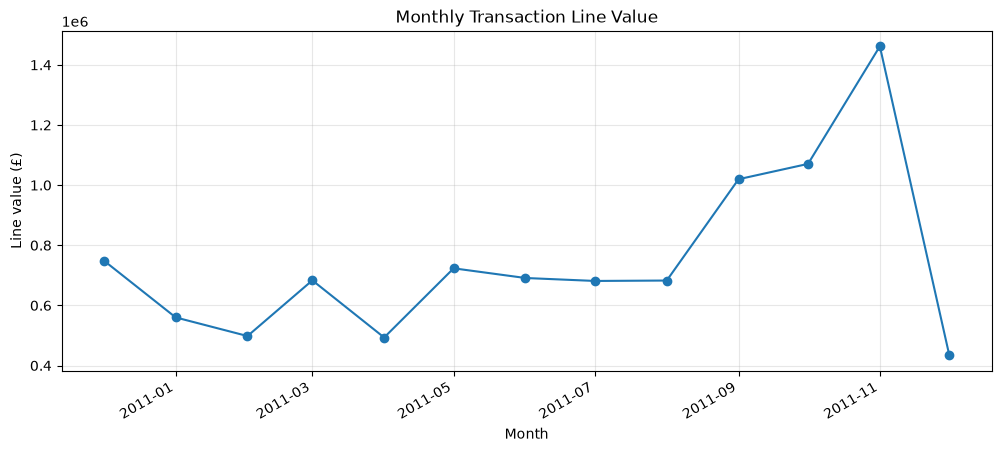

In [2]:
monthly = pd.read_csv(REPORTS / "monthly_sales.csv")
display(monthly)

monthly["month"] = pd.to_datetime(monthly["month"])
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month"], monthly["sales_value"], marker="o")
ax.set_title("Monthly Transaction Line Value")
ax.set_xlabel("Month")
ax.set_ylabel("Line value (£)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 3. Monthly growth

In [3]:
display(monthly[["month", "sales_value", "mom_growth_percent"]])

print(
    "Caution: December 2011 covers only the first nine days "
    "of the month and must not be compared with full months "
    "as if it were complete."
)

,month,sales_value,mom_growth_percent
0,2010-12-01,748957.020,NaN
1,2011-01-01,560000.260,-25.23
2,2011-02-01,498062.650,-11.06
3,2011-03-01,683267.080,37.18
4,2011-04-01,493207.121,-27.82
5,2011-05-01,723333.510,46.66
6,2011-06-01,691123.120,-4.45
7,2011-07-01,681300.111,-1.42
8,2011-08-01,682680.510,0.20
9,2011-09-01,1019687.622,49.37


Caution: December 2011 covers only the first nine days of the month and must not be compared with full months as if it were complete.


## 4. Product performance

In [4]:
products = pd.read_csv(REPORTS / "product_sales_analysis.csv")
display(products.head(10))

,stockcode,description,positive_quantity,negative_quantity,net_quantity,positive_value,negative_value,net_transaction_line_value,transaction_rows,cancellation_rows
0,10002,INFLATABLE POLITICAL GLOBE,1040,-3,1037,759.89,0.0,759.89,73,0
1,10080,GROOVY CACTUS INFLATABLE,495,0,495,119.09,0.0,119.09,24,0
2,10120,DOGGY RUBBER,193,0,193,40.53,0.0,40.53,30,0
3,10123C,HEARTS WRAPPING TAPE,5,-18,-13,3.25,0.0,3.25,4,0
4,10123G,NaN,0,-38,-38,0.00,0.0,0.00,1,0
5,10124A,SPOTS ON RED BOOKCOVER TAPE,16,0,16,6.72,0.0,6.72,5,0
6,10124G,ARMY CAMO BOOKCOVER TAPE,17,0,17,7.14,0.0,7.14,4,0
7,10125,MINI FUNKY DESIGN TAPES,1296,0,1296,994.84,0.0,994.84,94,0
8,10133,COLOURING PENCILS BROWN TUBE,2867,-92,2775,1544.22,-4.2,1540.02,200,1
9,10134,NaN,0,-19,-19,0.00,0.0,0.00,1,0


## 5. Data quality and interpretation

Some stock codes may represent postage, adjustments, or other non-merchandise entries. Interpret product rankings using the documented classification rules.

In [5]:
non_merchandise_path = REPORTS / "non_merchandise_analysis.csv"
if non_merchandise_path.exists():
    display(pd.read_csv(non_merchandise_path))

,entry_category,stockcode,description,positive_value,negative_value,net_transaction_line_value,positive_quantity,negative_quantity,net_quantity,transaction_rows,cancellation_rows
0,Manual adjustment,M,Manual,78112.82,-146784.46,-68671.64,7231,-4066,3165,572,244
1,Postage,DOT,DOTCOM POSTAGE,206248.77,-3.29,206245.48,1708,-1,1707,710,1
2,Postage,POST,POSTAGE,78101.88,-11871.24,66230.64,6500,-147,6353,1256,126
